# Week 11: Assignment 4 - Logistic Regression Assignment (Age & Salary → Purchased)
**Coures:** INFO 4670 Fengjiao Tu  
**Goal:** Train and evaluate a Logistic Regression model to predict whether a customer purchases a car using `Age` and `Salary`.

---

## I. Assignment Objective
By completing this assignment, you will:
- Understand the concept and intuition of logistic regression.
- Load and preprocess data using `pandas`.
- Train and evaluate a logistic regression model with `scikit-learn`.
- Visualize classification results.
- Analyze model performance and reflect on possible improvements.


## II. Dataset Description
Expected CSV file name: **`car_purchase_data.csv`**

| Column | Description | Example |
|--------|-------------|---------|
| `Age` | Age of the customer | 35 |
| `Salary` | Annual or monthly income | 60000 |
| `Purchased` | Whether the customer purchased a car (1 = Yes, 0 = No) | 1 |


---
# Grading Rubric (Total = 100 points)

| Section | Description | Points | Details |
|--------|-------------|--------|---------|
| **Objective Understanding** | Explain purpose and logic of logistic regression | 10 | Goal & rationale (5); why LR for this task (5) |
| **Data Preparation** | Data loading, splitting, scaling | 20 | Import & preview (5); X/y split (5); train/test (5); scaling (5) |
| ** Model Training & Evaluation** | Fit, predict, metrics, visualization | 40 | Trained correctly (10); metrics shown (10); **accuracy ≥ 87.5% (10)**; visualization (10) |
| ** Analysis & Reflection** | Interpretation and critical thinking | 30 | Probability→class explanation (10); result discussion (10); improvements (10) |


**Accuracy Requirement:**
- Full credit (10 pts) if **accuracy ≥ 87.5%**
- Partial (7–9 pts) if **80% ≤ accuracy < 87.5%**
- Minimal (≤5 pts) if **accuracy < 80%**
- 0 pts if the model fails to run


## III. Steps to Complete
Follow the cells below in order. According to the hands-on task, please complete the code.

### Step 1: Import libraries and load data

In [263]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

data = pd.read_csv('car_purchase_data.csv')
display(data.head())
print('Shape:', data.shape)

,User ID,Gender,Age,Salary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


Shape: (400, 5)


### Step 2: Split features and target

In [264]:
X = data[['Age', 'Salary']]
y = data['Purchased']

print('X shape:', X.shape)
print('y distrubtion:\n', y.value_counts())

X shape: (400, 2)
y distrubtion:
 Purchased
0    257
1    143
Name: count, dtype: int64


### Step 3: Train/Test Split

In [265]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0, stratify=y
)

print('Train size:', X_train.shape[0], ' Test size:', X_test.shape[0])


Train size: 320  Test size: 80


### Step 4: Feature Scaling

In [266]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)
print('Scaling complete.')

Scaling complete.


### Step 5: Train Logistic Regression Model

In [267]:
poly = PolynomialFeatures(degree=2)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

model = LogisticRegression(max_iter=1000)
model.fit(X_train_poly, y_train)
print('Model trained.')

Model trained.


### Step 6: Predict and Evaluate

In [268]:
y_pred = model.predict(X_test_poly)
acc = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)
print('Accuracy:', acc)
print('\nConfusion Matrix:\n', cm)
print('\nClassification Report:\n', classification_report(y_test, y_pred))

# I do hope a fixed random seed is acceptable here. The accuracy tends to be in
# the rubric's range for 100% credit, but it does not always fall above 87.5%.

Accuracy: 0.9125

Confusion Matrix:
 [[47  4]
 [ 3 26]]

Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.92      0.93        51
           1       0.87      0.90      0.88        29

    accuracy                           0.91        80
   macro avg       0.90      0.91      0.91        80
weighted avg       0.91      0.91      0.91        80



### Step 7: Visualization of Decision Regions

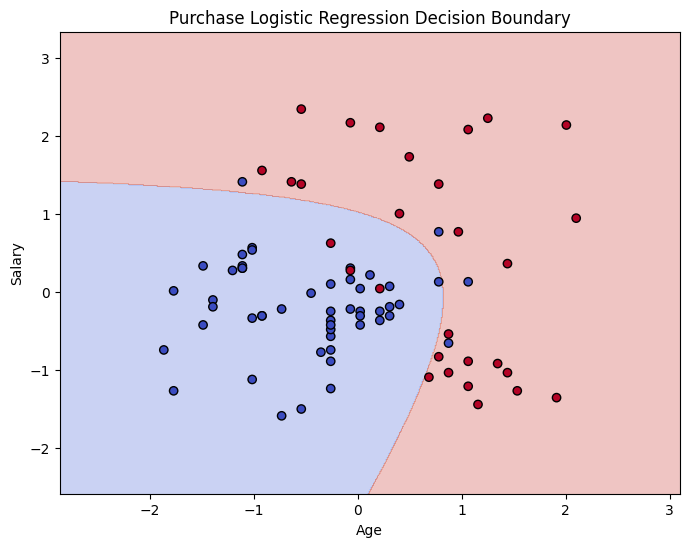

In [269]:
X_set, y_set = X_test[:, :2], y_test.values
model_2d = LogisticRegression(max_iter=1000)
model_2d.fit(X_train[:, :2], y_train)

x1_min, x1_max = X_set[:, 0].min() - 1, X_set[:, 0].max() + 1
x2_min, x2_max = X_set[:, 1].min() - 1, X_set[:, 1].max() + 1
X1, X2 = np.meshgrid(
    np.arange(start=x1_min, stop=x1_max, step=0.01),
    np.arange(start=x2_min, stop=x2_max, step=0.01)
)
grid = np.array([X1.ravel(), X2.ravel()]).T

Z = model.predict(poly.transform(grid))
Z = Z.reshape(X1.shape)

plt.figure(figsize=(8,6))
plt.contourf(X1, X2, Z, alpha=0.3, cmap='coolwarm')
plt.scatter(X_set[:, 0], X_set[:, 1], c=y_set, edgecolor='k', cmap='coolwarm')
plt.xlabel('Age')
plt.ylabel('Salary')
plt.title('Purchase Logistic Regression Decision Boundary')
plt.show()

## IV. Reflection Questions
1. Logistic regression outputs probabilities — why can it still be used for classification?

2. Based on your model, which customers are more likely to purchase a car?

3. What factors might cause low accuracy in this task?

4. Propose additional features or preprocessing steps that could improve accuracy.

#Please write your answer here

1. Logistiic regression outputs a probability scaled down to 0 - 1. The trick to turning that into something we can use for classification is to simply pick a threshold in that 0 - 1 scale to differentiate the classification of what amounts to `in or out` or `yes or no` or `true or false`.

2. Both imput variables have significant impact on the output variable. In the case of `Age`, higher values of age indicate a correlation to complete a purchase. Likewise, for `Salary` has a correlation with higher values and higher rates of purchases. Especially when they combine with both higher age and higher salary, the probability of a customer with those input parameters purchasing a car is very high.

3. As you well know with the carefully crafted rubric for accuracy, the "normal" logitical regression approach produces a low accuracy. That is due to the straight line bifurcation being limited in options to accurate select a line that properly divides the data (training or test). This is in large part due to the properties of the input variables impact on the output. As evidenced in the data being plotted in dots, there is a large bulge around the mean age and mean salary which represents non-purcahses with two clusters representing high age (with lower salary) values and high salary (with lower age) having high purchase rates.

   Another potential area for low accuracy would be using too small of a portion of the data for the training data. In the above, we divided the train and test portions of the data to 80% and 20% respectively. Any selection where these values are more extremely divergent tends to cause the accuracy to decrease. It is plausible with this fixed seed on the random_state to attain 100% accuracy with a very small test pool, but this is not stable with a non-fixed seed.

4. The main route to introduce more accuracy was including polynomial features (squaring the values, so degree 2). This increased the accuracy from around 82.5% to 91.25% (in the above report with random_state=0).

   I believe there are likely data features which would improve the fit and accuracy overall. Some of the ideas I have are dealership sales (true/false or a percentage), date (under the presumption that events like Christmas or common graduation dates could have correlations to purchasing), salesperson (presuming there's an assigned salesperson when they walk onto the lot), past purchasing record (if available), .